# Attention Knockout: test which input route supports an answer

This notebook computes real knockout effects on one raw GQA case with a small pretrained SmolVLM. It never reads saved measurements. The method replaces selected masked attention scores with negative infinity before softmax, reruns the model, and measures a fixed answer score. No training is required. Install `pip install "vlmprobe[transformers,visualization,notebooks]"`; open in a repository checkout and use a GPU when available.

## Runtime setup

Run the setup cell first. In Google Colab it obtains a Git checkout and installs
the notebook dependencies; local execution keeps the existing environment.
Choose a GPU runtime when required by the walkthrough.

Optional environment settings: VLM_PROBING_REPOSITORY (default
ubc-tea/vlm-probe), VLM_PROBING_REF (default main), and
VLM_PROBING_COLAB_DIR (default /content/vlm-probe). The repository and ref
select a new checkout. An existing vlmprobe checkout is reused at its current
commit without discarding local changes. The cell prints that commit.

All input construction, calibration, probing and plotting remain visible in
the analysis cells below. Restart the runtime only if the setup cell reports
that an already imported package or checkout has changed.


In [ ]:
#@title Runtime setup (Colab only; expand to inspect)
# Environment setup only; the analysis workflow is visible in the cells below.
import os as _nb_setup_os
import sys as _nb_setup_sys

_nb_setup_in_colab = (
    "google.colab" in _nb_setup_sys.modules
    or bool(_nb_setup_os.environ.get("COLAB_RELEASE_TAG"))
)
if _nb_setup_in_colab:
    import hashlib as _nb_setup_hashlib
    import importlib as _nb_setup_importlib
    import importlib.metadata as _nb_setup_metadata
    from pathlib import Path as _NBSetupPath
    import re as _nb_setup_re
    import subprocess as _nb_setup_subprocess

    _nb_setup_repo = _nb_setup_os.environ.get(
        "VLM_PROBING_REPOSITORY", "ubc-tea/vlm-probe"
    )
    _nb_setup_ref = _nb_setup_os.environ.get("VLM_PROBING_REF", "main")
    if not _nb_setup_re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9-]*/[A-Za-z0-9][A-Za-z0-9_.-]*",
        _nb_setup_repo,
    ):
        raise ValueError("VLM_PROBING_REPOSITORY must be a GitHub owner/repository.")
    if not _nb_setup_ref or _nb_setup_ref.startswith("-") or any(
        character.isspace() for character in _nb_setup_ref
    ):
        raise ValueError("VLM_PROBING_REF must be a nonempty Git ref or commit SHA.")
    _nb_setup_checkout = _NBSetupPath(
        _nb_setup_os.environ.get("VLM_PROBING_COLAB_DIR", "/content/vlm-probe")
    ).expanduser().resolve()
    _nb_setup_existing = _nb_setup_checkout.exists()
    if not _nb_setup_existing:
        _nb_setup_checkout.parent.mkdir(parents=True, exist_ok=True)
        _nb_setup_subprocess.check_call([
            "git", "clone", "--depth=1", "--no-checkout",
            "https://github.com/" + _nb_setup_repo + ".git",
            str(_nb_setup_checkout),
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout), "fetch",
            "--depth=1", "origin", _nb_setup_ref,
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout),
            "checkout", "--detach", "FETCH_HEAD",
        ])

    # Validate before changing directories or installing anything. In
    # particular, never reset, clean or overwrite an existing user directory.
    _nb_setup_pyproject = _nb_setup_checkout / "pyproject.toml"
    _nb_setup_init = _nb_setup_checkout / "src/vlm_probing/__init__.py"
    if (
        not _nb_setup_checkout.is_dir()
        or not _nb_setup_pyproject.is_file()
        or not _nb_setup_init.is_file()
        or not (_nb_setup_checkout / "src/vlmprobe/__init__.py").is_file()
        or not (_nb_setup_checkout / "src/vlm_probing/prober.py").is_file()
        or not (_nb_setup_checkout / "demos").is_dir()
    ):
        raise RuntimeError(
            "The setup directory is not a vlmprobe checkout. It was left "
            "untouched. Set VLM_PROBING_COLAB_DIR to a new directory."
        )
    _nb_setup_project_section = _nb_setup_re.search(
        r"(?ms)^\[project\][^\n]*\n(.*?)(?=^\[|\Z)",
        _nb_setup_pyproject.read_text(),
    )
    if not _nb_setup_project_section or not _nb_setup_re.search(
        r"""(?m)^name\s*=\s*["']vlmprobe["']\s*$""",
        _nb_setup_project_section.group(1),
    ):
        raise RuntimeError(
            "The existing directory declares a different project; it was "
            "left untouched. Choose another VLM_PROBING_COLAB_DIR."
        )

    def _nb_setup_git(*arguments):
        return _nb_setup_subprocess.check_output(
            ["git", "-C", str(_nb_setup_checkout), *arguments], text=True
        ).strip()

    try:
        _nb_setup_git_root = _NBSetupPath(
            _nb_setup_git("rev-parse", "--show-toplevel")
        ).resolve()
        _nb_setup_sha = _nb_setup_git("rev-parse", "HEAD")
        _nb_setup_dirty = bool(_nb_setup_git("status", "--porcelain"))
    except _nb_setup_subprocess.CalledProcessError as _nb_setup_error:
        raise RuntimeError(
            "The existing vlmprobe directory is not a readable Git checkout; "
            "it was not reset or replaced. Choose another setup directory."
        ) from _nb_setup_error
    if _nb_setup_git_root != _nb_setup_checkout:
        raise RuntimeError(
            "The setup directory is inside another Git project, not the "
            "vlmprobe checkout root. Choose another setup directory."
        )
    if _nb_setup_existing:
        print(
            "Reusing the existing vlmprobe checkout; repository/ref settings "
            "apply only to a new checkout."
        )
    print("vlmprobe checkout:", _nb_setup_checkout, "@", _nb_setup_sha)
    if _nb_setup_dirty:
        print("Local checkout changes are preserved.")

    _nb_setup_distributions = {
        "vlmprobe": "vlmprobe",
        "vlm_probing": "vlmprobe",
        "torch": "torch",
        "transformers": "transformers",
        "numpy": "numpy",
        "PIL": "Pillow",
        "safetensors": "safetensors",
        "huggingface_hub": "huggingface-hub",
    }
    _nb_setup_loaded = {
        name: (
            getattr(_nb_setup_sys.modules[name], "__version__", None),
            getattr(_nb_setup_sys.modules[name], "__file__", None),
        )
        for name in _nb_setup_distributions
        if name in _nb_setup_sys.modules
    }
    _nb_setup_extras = "transformers,visualization,sae,evaluation"
    _nb_setup_signature = (
        str(_nb_setup_checkout), _nb_setup_sha, _nb_setup_sys.executable,
        _nb_setup_hashlib.sha256(_nb_setup_pyproject.read_bytes()).hexdigest(),
        _nb_setup_extras,
    )
    _nb_setup_previous = globals().get("_vlmprobe_colab_setup_state", {})
    if not isinstance(_nb_setup_previous, dict):
        _nb_setup_previous = {}
    _nb_setup_os.chdir(_nb_setup_checkout)
    if _nb_setup_previous.get("signature") != _nb_setup_signature:
        _nb_setup_subprocess.check_call([
            _nb_setup_sys.executable, "-m", "pip", "install", "-e",
            str(_nb_setup_checkout) + "[" + _nb_setup_extras + "]",
        ])
        _vlmprobe_colab_setup_state = {"signature": _nb_setup_signature}
    else:
        print("This runtime already prepared the same checkout and dependencies.")
    _nb_setup_source_path = str(_nb_setup_checkout / "src")
    if _nb_setup_source_path not in _nb_setup_sys.path:
        _nb_setup_sys.path.insert(0, _nb_setup_source_path)
    _nb_setup_importlib.invalidate_caches()

    _nb_setup_restart = []
    if (
        _nb_setup_previous.get("signature")
        and _nb_setup_previous["signature"] != _nb_setup_signature
        and any(name in _nb_setup_loaded for name in ("vlmprobe", "vlm_probing"))
    ):
        _nb_setup_restart.append(
            "the checkout or installation changed after vlmprobe was imported"
        )
    for _nb_setup_name, (_nb_setup_loaded_version, _nb_setup_origin) in _nb_setup_loaded.items():
        if _nb_setup_name in ("vlmprobe", "vlm_probing") and _nb_setup_origin:
            if not _NBSetupPath(_nb_setup_origin).resolve().is_relative_to(
                _nb_setup_checkout / "src"
            ):
                _nb_setup_restart.append(_nb_setup_name + " was imported from another checkout")
        if _nb_setup_loaded_version is not None:
            try:
                _nb_setup_installed_version = _nb_setup_metadata.version(
                    _nb_setup_distributions[_nb_setup_name]
                )
            except _nb_setup_metadata.PackageNotFoundError:
                continue
            if str(_nb_setup_loaded_version) != _nb_setup_installed_version:
                _nb_setup_restart.append(
                    _nb_setup_name + " " + str(_nb_setup_loaded_version)
                    + " is loaded; installed version is " + _nb_setup_installed_version
                )
    if _nb_setup_restart:
        raise RuntimeError(
            "Setup completed, but this runtime already imported an older or "
            "different package. Restart the Colab runtime, rerun this setup "
            "cell, and then run the analysis cells. Details: "
            + "; ".join(_nb_setup_restart)
        )
    print("Setup complete. Run the analysis cells below.")
else:
    print("Local runtime: using the existing checkout and environment.")


## 1. Construct the complete input and target

The image, question and annotation are raw dataset inputs. The complete annotated answer defines a fixed teacher-forced log-probability target. These are conditional answer-score interventions, not free-generation output comparisons.

In [1]:
from pathlib import Path
import json
import os
import numpy as np
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor
from vlmprobe import Prober, ProbeInputs, TokenLayout, SequenceLogProb
from vlmprobe import visualization as viz
import matplotlib.pyplot as plt

# Install: pip install "vlmprobe[transformers,visualization,notebooks]"
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "demos/assets/gqa_samples.json").is_file())
# This manifest contains raw GQA questions/answers and image provenance only.
sample = json.loads((ROOT / "demos/assets/gqa_samples.json").read_text())[0]
image = Image.open(ROOT / "demos/assets/images" / sample["image_path"]).convert("RGB")
question = sample["question"]
answer = sample["answer"]
model_id = os.environ.get("VLM_PROBING_MODEL", "HuggingFaceTB/SmolVLM-500M-Instruct")
device = os.environ.get("VLM_PROBING_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
model = AutoModelForImageTextToText.from_pretrained(
    model_id, dtype=torch.float32, attn_implementation="eager",
).to(device).eval()
processor = AutoProcessor.from_pretrained(model_id)
# One image tile keeps this tutorial small and gives one unambiguous patch grid.
processor.image_processor.do_image_splitting = False
processor.image_processor.size = {"longest_edge": model.config.vision_config.image_size}
probe = Prober(model, processor)
messages = [{"role": "user", "content": [
    {"type": "image"}, {"type": "text", "text": question},
]}]
prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
base = probe.prepare(prompt=prompt, image=image, device=device)
with torch.no_grad():
    generated = model.generate(**base.kwargs, max_new_tokens=12, do_sample=False)
print("Question:", question)
print("Generated:", processor.tokenizer.decode(generated[0, base.kwargs["input_ids"].shape[1]:], skip_special_tokens=True))

# Teacher-force the entire annotated answer; never assume an answer is one token.
scored = probe.prepare(prompt=prompt + answer, image=image, device=device)
ids = scored.kwargs["input_ids"]
prefix_length = base.kwargs["input_ids"].shape[1]
assert torch.equal(ids[:, :prefix_length], base.kwargs["input_ids"]), "Check the tokenizer's prompt boundary"
valid = scored.kwargs["attention_mask"].bool()
visual = ids.eq(model.config.image_token_id) & valid
prompt_mask = valid.clone()
prompt_mask[:, prefix_length:] = False
answer_mask = valid & ~prompt_mask
query_mask = torch.zeros_like(valid)
query_mask[:, :-1] = answer_mask[:, 1:]  # Rows predicting the selected answer tokens.
inputs = ProbeInputs(scored.kwargs, TokenLayout(valid, visual, prompt_mask, ids))
metric = SequenceLogProb(answer_mask, reduction="sum")
print("Annotated answer tokens:", processor.tokenizer.convert_ids_to_tokens(ids[answer_mask].tolist()))
print("Input token count:", ids.shape[1], "| visual slots:", int(visual.sum()))
output_dir = Path(os.environ.get("VLM_PROBING_OUTPUT", "outputs/vlm-attention-tutorial"))
output_dir.mkdir(parents=True, exist_ok=True)


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

Question: Is the shirt black or yellow?
Generated:  The shirt is black.
Annotated answer tokens: ['yellow']
Input token count: 83 | visual slots: 64


## 2. Block one route per layer and plot measured changes

Each layer is tested independently (`joint=False`). Negative values mean this route’s removal lowers support for the annotated answer; positive values mean it raises support. Earlier-text keys keep the prediction token’s self edge legal, so no query loses every legal key. In this one-token annotated answer, `last_prompt` is the row predicting that answer; for multi-token route tests, explicitly use `query_mask` to include all answer-prediction rows.

Image to answer prediction baseline tensor([[-16.4361]]) effect tensor([[-0.0153],
        [ 0.2198],
        [-0.1231],
        [ 0.0237],
        [ 0.0947],
        [-0.1904],
        [-0.0864],
        [ 0.1521],
        [ 0.2050],
        [-0.3183],
        [ 0.4785],
        [-0.0182],
        [-0.0713],
        [-0.0245],
        [ 0.1064],
        [-0.0961],
        [ 0.0025],
        [-0.0153],
        [ 0.0870],
        [-0.0188],
        [-0.0867],
        [-0.0165],
        [-0.0377],
        [ 0.2006],
        [ 0.0225],
        [-0.0133],
        [ 0.0564],
        [ 0.4914],
        [-0.0679],
        [-0.1007],
        [ 0.0937],
        [ 0.1176]])


Earlier text to answer prediction baseline tensor([[-16.4361]]) effect tensor([[ 0.1200],
        [ 2.1638],
        [ 0.3713],
        [ 0.1185],
        [-0.2332],
        [ 1.5966],
        [ 3.3760],
        [ 1.5397],
        [ 1.1940],
        [ 2.4379],
        [-0.1012],
        [-0.3228],
        [ 1.1112],
        [ 2.9312],
        [-3.2583],
        [ 0.8408],
        [ 2.0978],
        [ 0.5882],
        [-0.3762],
        [ 2.6728],
        [ 0.9579],
        [ 0.0844],
        [ 1.5018],
        [-0.8725],
        [-0.8156],
        [ 0.9665],
        [-1.1451],
        [-1.8530],
        [ 0.2755],
        [ 0.2540],
        [-0.0288],
        [-0.3470]])


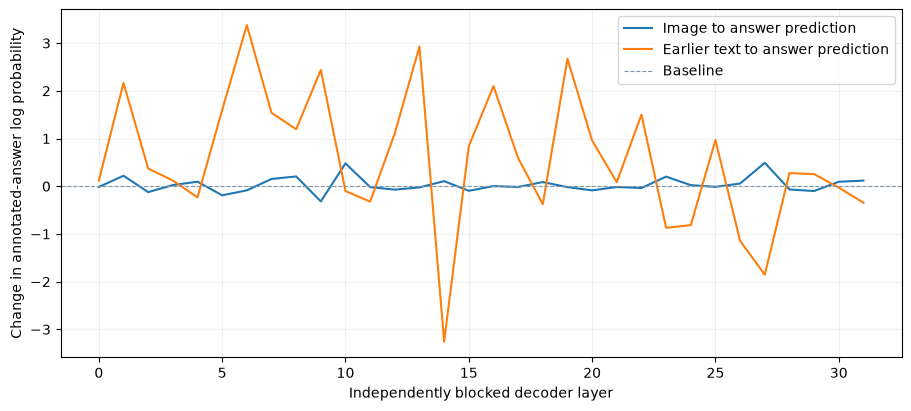

In [2]:
layers = probe.describe()["methods"]["causal.knockout"]["sites"]
assert layers, "This model needs editable pre-softmax attention scores"
last_position = prefix_length - 1
question_keys = inputs.layout.valid & ~inputs.layout.visual
question_keys[:, last_position:] = False  # Retain a legal self key at prediction.
routes = {
    "Image to answer prediction": ("last_prompt", "visual"),
    "Earlier text to answer prediction": ("last_prompt", question_keys),
}
curves = {}
for label, (queries, keys) in routes.items():
    result = probe.causal.knockout(layers=layers, queries=queries, keys=keys, joint=False).run(inputs, metric=metric)
    print(label, "baseline", result.tensors["baseline_score"][:1], "effect", result.tensors["effect"])
    result.save(output_dir / label.lower().replace(" ", "-"))
    curves[label] = result
ax = viz.plot_intervention_curves(curves, tensor="effect", baseline=0,
    xlabel="Independently blocked decoder layer", ylabel="Change in annotated-answer log probability")
ax.figure.savefig(output_dir / "attention-knockout.png", dpi=160, bbox_inches="tight")
plt.show()

# Identity control: multiplying visual probability mass by one must preserve the score.
control = probe.attention.reweight(layers=[layers[0]], queries="last_prompt", keys="visual", weight=1.0).run(inputs, metric=metric)
torch.testing.assert_close(control.tensors["effect"], torch.zeros_like(control.tensors["effect"]), atol=1e-5, rtol=0)


## Optional joint-window experiment

For a measured window effect, call `probe.causal.knockout(layers=window, queries="last_prompt", keys="visual", joint=True).run(inputs, metric=metric)`. Build each window explicitly, and do not sum independent-layer effects to predict a joint effect. Knockout tests a route under this intervention; it does not establish a unique minimal circuit. [API, parameters and original method](../docs/methods/attention_knockout.md).